### DBSCAN (Density-Based Spatial Clustering of Applications with Noise) — это алгоритм кластеризации, основанный на плотности точек в пространстве. В отличие от K-Means или иерархической кластеризации, DBSCAN не требует заранее задавать число кластеров, а сам определяет число кластеров в процессе обучения, и хорошо справляется с кластерами сложной формы.

Основные принципы DBSCAN
DBSCAN группирует точки в кластеры, основываясь на их плотности. В основе алгоритма лежат два параметра:

ε (эпсилон) — радиус окрестности точки.
minPts — минимальное число точек в окрестности, чтобы точка считалась «основной» (core point).
Алгоритм определяет три типа точек:

Основные точки (Core points) — имеют не менее minPts соседей в радиусе ε. Они формируют кластеры.
Граничные точки (Border points) — находятся в ε-окрестности основной точки, но сами не имеют достаточного количества соседей. Они принадлежат кластеру, но не являются его центром.
Шумовые точки (Noise points) — не являются ни основными, ни граничными. Они считаются выбросами и не входят в кластеры.

![alt text](asset-v1_SkillFactory+MIFIML-2sem+2025+type@asset+block@MIFIML_CML_7M_13.png)

Принцип работы алгоритма:

Определяем параметры minPts и eps.
Произвольно выбирается начальная точка из данных, ее окрестности определяются в пределах расстояния eps, и если в пределах этой окрестности есть не менее minPts точек, то эта точка данных классифицируется как основная точка.
Алгоритм продолжает этот процесс из пункта 2 для всех точек. Он находит соседние точки данных в пределах eps и идентифицирует основные точки. Для каждой основной точки, если эта точка не назначена кластеру, алгоритм создает новый кластер.
Затем алгоритм находит все соседние точки, используя метрики расстояния; и если для рассматриваемой точки данных есть не менее minPts точек в пределах eps, то все эти точки являются частью одного кластера.
Алгоритм проходит по непосещенным точкам. Если они не являются частью какого-либо кластера, то помечает их как выбросы/шум.
Алгоритм завершается, когда посещены все точки данных.

![alt text](asset-v1_SkillFactory+MIFIML-2sem+2025+type@asset+block@MIFIML_CML_7M_14.png)

Плюсы DBSCAN
Не требует заранее задавать число кластеров.
Находит кластеры произвольной формы (в отличие от K-Means, который работает лучше с круглыми кластерами).
Устойчив к выбросам и шуму.
Не зависит от начальной инициализации центроидов (как K-Means).
Минусы DBSCAN
Чувствителен к выбору параметров ε и minPts.
Плохо работает с данными разной плотности (может объединять плотные кластеры в один).
Сложность O(n²) наивной реализации (но можно оптимизировать до O(n log n)).

Посмотрим на практическое применение алгоритма на сгенерированном наборе данных, для визуального представления принципа работы обучим три разных алгоритма на трех разных значениях epsilon:



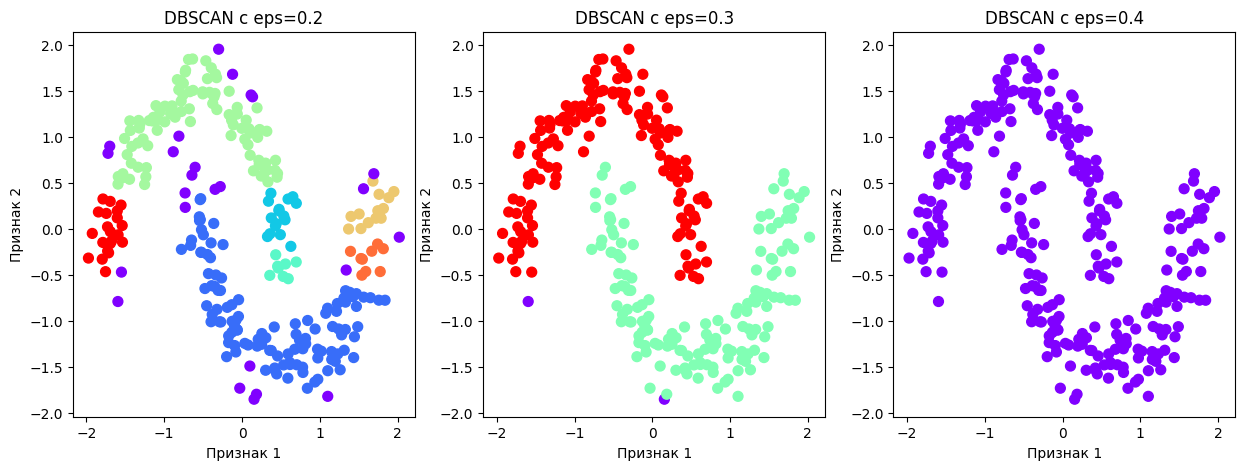

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

# Создаем данные с кластерами в форме полумесяцев
X, _ = make_moons(n_samples=300, noise=0.1, random_state=42)
X = StandardScaler().fit_transform(X)  # Стандартизируем данные

# Создаем подграфики
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Значения eps для тестирования
eps_values = [0.2, 0.3, 0.4]

# Запускаем DBSCAN с разными eps
for i, e in enumerate(eps_values):
    dbscan = DBSCAN(eps=e, min_samples=5)
    labels = dbscan.fit_predict(X)

    # Визуализация результатов
    axes[i].scatter(X[:, 0], X[:, 1], c=labels, cmap="rainbow", s=50)
    axes[i].set_xlabel("Признак 1")
    axes[i].set_ylabel("Признак 2")
    axes[i].set_title(f"DBSCAN с eps={e}")

plt.show()

Все точки, которые алгоритм, отмечает как шумовые будут иметь label = -1 , на графике они обозначены фиолетовым цветом. Таким образом, видно, что DBSCAN крайне чувствителен к правильному подбору гиперпараметром.

Как выбрать параметры DBSCAN?

Выбор ε (эпсилон) — можно использовать график расстояний k-соседей (k-distance plot). Найти «колено» на графике и взять соответствующее значение ε.

![alt text](asset-v1_SkillFactory+MIFIML-2sem+2025+type@asset+block@MIFIML_CML_7M_16.png)

Выбор min_samples: обычно min_samples = 2 * (количество признаков). Можно попробовать 5-10 и выбрать лучшее значение.
DBSCAN особенно полезен для нахождения кластеров произвольной формы и работы с шумными данными. Однако он требует внимательного подбора параметров ε и min_samples, а также плохо справляется с данными разной плотности. Часто алгоритм используется как вспомогательный инструмент для поиска, анализа выбросов в данных.